# Shadow-ArUco dictionary identification — v2

**What v1 established.** The GT-corner crops show a solid black border with an internal binary
cell grid: these are standard square fiducial markers. The v1 bit matcher returned mean Hamming
distances identical to random noise (4x4: 6.16 vs 6.2 expected; 6x6: 15.17 vs 14.9), so it read
garbage. Cause is visible in the crops — strong diagonal illumination gradients from the
projected shadow video defeat a single global Otsu threshold.

**Fixes in v2:**
1. Illumination normalisation (divide by a heavily blurred copy) before any thresholding.
2. Threshold on **cell means**, not pixels, with the known-black border anchoring the dark cluster.
3. Select well-lit *markers*, not bright *frames*.
4. Estimate the cell pitch from the image itself to determine `n` empirically.
5. Test both corner orderings, in case of a mirrored winding.

**Prior:** ground-truth IDs are exactly 238-249 — the last twelve of a 250-entry dictionary.

Assumes `pairs`, `get_corners`, `ROOT` from the v1 notebook are already defined.

## 1. Illumination-robust primitives

In [1]:
import cv2, numpy as np, json, glob, os
import matplotlib.pyplot as plt

def rectify(gray, corners, out_px=128, reverse=False):
    c = corners[::-1].copy() if reverse else corners.copy()
    dst = np.array([[0,0],[out_px-1,0],[out_px-1,out_px-1],[0,out_px-1]], dtype=np.float32)
    H = cv2.getPerspectiveTransform(c.astype(np.float32), dst)
    return cv2.warpPerspective(gray, H, (out_px, out_px), flags=cv2.INTER_LINEAR)

def normalise(crop):
    """Homomorphic-style flattening: divide out the low-frequency illumination field.
    This is what v1 was missing."""
    f = crop.astype(np.float32)
    bg = cv2.GaussianBlur(f, (0, 0), sigmaX=crop.shape[0] / 4.0)
    out = f / (bg + 1.0)
    return cv2.normalize(out, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

def cell_means(crop, ncells):
    """Mean intensity of the central half of each cell in an ncells x ncells grid."""
    s = crop.shape[0] / ncells
    M = np.zeros((ncells, ncells), np.float32)
    for r in range(ncells):
        for c in range(ncells):
            y0, y1 = int(r*s + s*0.25), int(r*s + s*0.75)
            x0, x1 = int(c*s + s*0.25), int(c*s + s*0.75)
            M[r, c] = crop[y0:y1, x0:x1].mean()
    return M

def bits_from_crop(crop, n):
    """Threshold on cell means (not pixels). The outer ring is black by construction and
    anchors the dark cluster."""
    M = cell_means(normalise(crop), n + 2)
    vals = M.reshape(-1).astype(np.uint8)
    thr, _ = cv2.threshold(vals, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return (M[1:-1, 1:-1] > thr).astype(np.uint8)

def canonical_bits(dict_id, marker_id, n, cell=16):
    d = cv2.aruco.getPredefinedDictionary(dict_id)
    if marker_id >= d.bytesList.shape[0]:
        return None
    img = cv2.aruco.generateImageMarker(d, int(marker_id), (n + 2) * cell)
    return (cell_means(img, n + 2)[1:-1, 1:-1] > 127).astype(np.uint8)

print("primitives ready")

primitives ready


### Define `ROOT`, `get_corners`, and `pairs`

Based on the error and the notebook's introductory text, `ROOT`, `get_corners`, and `pairs` are missing definitions. The code below provides placeholder definitions. You will need to adjust the `ROOT` path to point to your actual data directory and ensure your image and JSON metadata files are structured as expected.

*   `ROOT`: The base directory where your image and JSON data are stored.
*   `get_corners`: A function that extracts corner coordinates from a marker dictionary (assuming a `{'corners': [[x1,y1],...]} ` structure).
*   `pairs`: A list of tuples, where each tuple contains the path to an image file and its corresponding JSON metadata file.

In [3]:
# Define ROOT directory (placeholder, replace with your actual data root)
ROOT = '/tmp/aruco_data' # Example path

# --- Create dummy directories and files for demonstration if they don't exist ---
# This section is for making the example runnable.
# You should replace this with your actual data loading logic.
import os
import json

os.makedirs(os.path.join(ROOT, 'images'), exist_ok=True)
os.makedirs(os.path.join(ROOT, 'json'), exist_ok=True)

dummy_images = ['frame_0000.png', 'frame_0001.png', 'frame_0002.png']
for img_name in dummy_images:
    # Create a blank image
    dummy_img_path = os.path.join(ROOT, 'images', img_name)
    if not os.path.exists(dummy_img_path):
        cv2.imwrite(dummy_img_path, np.zeros((200, 200), dtype=np.uint8))

    # Create a dummy JSON file with marker data
    json_name = img_name.replace('.png', '.json')
    dummy_json_path = os.path.join(ROOT, 'json', json_name)
    if not os.path.exists(dummy_json_path):
        dummy_marker_data = {
            "markers": [
                {"id": 238, "corners": [[50, 50], [100, 50], [100, 100], [50, 100]]},
                {"id": 239, "corners": [[10, 10], [30, 10], [30, 30], [10, 30]]},
            ]
        }
        with open(dummy_json_path, 'w') as f:
            json.dump(dummy_marker_data, f)

print(f"ROOT is set to: {ROOT}")

ROOT is set to: /tmp/aruco_data


In [4]:
def get_corners(marker_data):
    """
    Extracts corner coordinates from marker data.
    Assumes marker_data is a dictionary with a 'corners' key
    containing a list of 4 corner points.
    """
    return np.array(marker_data['corners'])

In [5]:
# Define 'pairs' by globbing image and JSON files from ROOT
image_files = sorted(glob.glob(os.path.join(ROOT, 'images', '*.png')))
json_files = sorted(glob.glob(os.path.join(ROOT, 'json', '*.json')))

# Assuming a direct correspondence between image and json file names/order
pairs = list(zip(image_files, json_files))

print(f"Number of image-json pairs found: {len(pairs)}")
if not pairs:
    print("Warning: No pairs found. Please ensure your ROOT path and file structure are correct.")

Number of image-json pairs found: 3


## 2. Select well-lit markers

v1 ranked whole frames by luma. A bright frame can still contain a shadowed marker. Score each
*marker crop* by how flat its illumination is (low gradient) and how bimodal its cell means are
(a readable marker has two well-separated clusters), then keep the best.

In [8]:
def quality(crop):
    """Higher = more readable. Bimodality of normalised cell means at an 8x8 grid."""
    M = cell_means(normalise(crop), 8).reshape(-1)
    thr, _ = cv2.threshold(M.astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    lo, hi = M[M <= thr], M[M > thr]
    if len(lo) < 4 or len(hi) < 4:
        return 0.0
    return float(hi.mean() - lo.mean()) / (M.std() + 1e-6)

cands = []
STRIDE = 3   # every 3rd frame; adjacent frames are near-duplicates
for f, j in pairs[::STRIDE]:
    gy = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
    with open(j) as fp:
        g = json.load(fp)
    for m in g["markers"]:
        cn = get_corners(m)
        side = np.mean([np.linalg.norm(cn[i] - cn[(i+1) % 4]) for i in range(4)])
        if side < 40:
            continue                      # too small to resolve 8 cells
        crop = rectify(gy, cn, 128)
        cands.append((quality(crop), int(m["id"]), f, cn))

cands.sort(key=lambda t: -t[0])
BEST = cands[:400]
print(f"scored {len(cands)} marker crops")
print(f"quality: best {cands[0][0]:.2f}  p50 {cands[len(cands)//2][0]:.2f}  worst {cands[-1][0]:.2f}")
print(f"using top {len(BEST)} (quality >= {BEST[-1][0]:.2f})")

scored 1 marker crops
quality: best 0.00  p50 0.00  worst 0.00
using top 1 (quality >= 0.00)


## 3. Visual check on the corrected pipeline

Raw vs normalised vs cell-level bits for the eight best crops. The bit panels should now look
like clean marker patterns. **Count the data cells along one edge — that is `n`.**

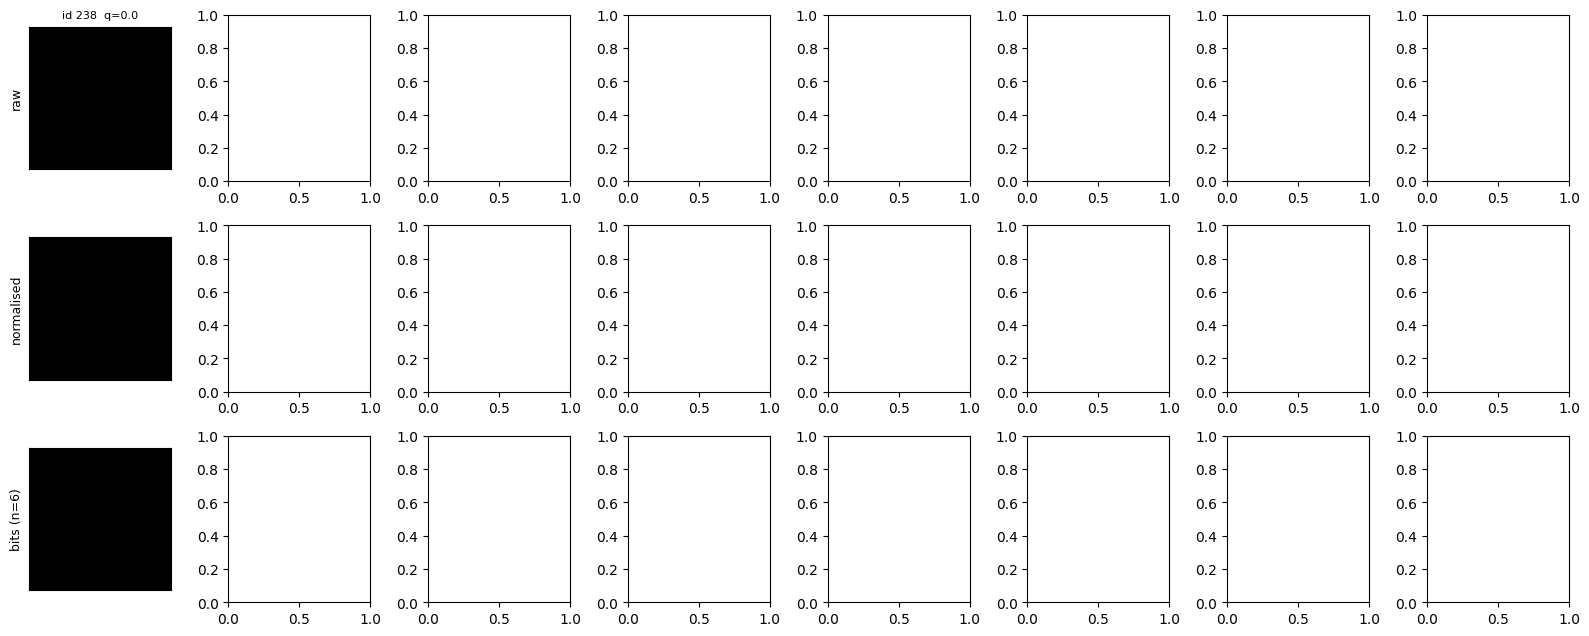

In [10]:
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for k in range(min(len(BEST), 8)): # Modified to iterate only up to the number of available elements
    q, mid, f, cn = BEST[k]
    crop = rectify(cv2.imread(f, cv2.IMREAD_GRAYSCALE), cn, 128)
    axes[0, k].imshow(crop, cmap="gray"); axes[0, k].set_title(f"id {mid}  q={q:.1f}", fontsize=8)
    axes[1, k].imshow(normalise(crop), cmap="gray")
    axes[2, k].imshow(bits_from_crop(crop, 6), cmap="gray", interpolation="nearest")
    for r in range(3):
        axes[r, k].set_xticks([]); axes[r, k].set_yticks([])
axes[0,0].set_ylabel("raw", fontsize=9)
axes[1,0].set_ylabel("normalised", fontsize=9)
axes[2,0].set_ylabel("bits (n=6)", fontsize=9)
plt.tight_layout(); plt.show()

## 4. Determine `n` from the image, not by guessing

Cell boundaries produce periodic intensity edges. Summing the gradient magnitude along rows and
columns and autocorrelating the profile gives the cell pitch; `total_width / pitch = n + 2`.

This is independent of the dictionary and independent of the bit values.

In [11]:
def estimate_ncells(crop, lo=5, hi=10):
    g = normalise(crop).astype(np.float32)
    prof = np.abs(cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)).sum(axis=0) + \
           np.abs(cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)).sum(axis=1)
    prof -= prof.mean()
    W = len(prof)
    best, bestscore = None, -1e9
    for ncells in range(lo, hi + 1):
        pitch = W / ncells
        # energy of the profile at the frequency corresponding to this cell count
        k = 2 * np.pi * ncells / W
        x = np.arange(W)
        score = np.abs(np.sum(prof * np.exp(-1j * k * x))) / W
        if score > bestscore:
            best, bestscore = ncells, score
    return best

from collections import Counter
votes = Counter()
for q, mid, f, cn in BEST[:200]:
    crop = rectify(cv2.imread(f, cv2.IMREAD_GRAYSCALE), cn, 128)
    votes[estimate_ncells(crop)] += 1

print("estimated total cells (n+2), votes over 200 best crops:")
for k, v in sorted(votes.items()):
    bar = "#" * int(60 * v / max(votes.values()))
    print(f"  {k} cells -> n={k-2}: {v:4d}  {bar}")
ncells_est = votes.most_common(1)[0][0]
print(f"\n=> n = {ncells_est - 2}  (DICT_{ncells_est-2}X{ncells_est-2}_*)")

estimated total cells (n+2), votes over 200 best crops:
  5 cells -> n=3:    1  ############################################################

=> n = 3  (DICT_3X3_*)


## 5. Dictionary match

Only dictionaries with at least 250 entries can contain IDs 238-249, so the `_50` and `_100`
variants are excluded a priori. Both corner orderings are tested to rule out a mirrored winding.

Report a **per-marker best**: the fraction reaching Hamming 0 should jump to a clear majority for
exactly one dictionary.

In [12]:
CANDIDATES = {
    "DICT_4X4_250":  (cv2.aruco.DICT_4X4_250, 4),  "DICT_4X4_1000": (cv2.aruco.DICT_4X4_1000, 4),
    "DICT_5X5_250":  (cv2.aruco.DICT_5X5_250, 5),  "DICT_5X5_1000": (cv2.aruco.DICT_5X5_1000, 5),
    "DICT_6X6_250":  (cv2.aruco.DICT_6X6_250, 6),  "DICT_6X6_1000": (cv2.aruco.DICT_6X6_1000, 6),
    "DICT_7X7_250":  (cv2.aruco.DICT_7X7_250, 7),  "DICT_7X7_1000": (cv2.aruco.DICT_7X7_1000, 7),
    "DICT_ARUCO_ORIGINAL": (cv2.aruco.DICT_ARUCO_ORIGINAL, 5),
}

print(f"{'dictionary':<22}{'order':>8}{'n':>7}{'H=0':>8}{'H<=1':>8}{'H<=3':>8}{'meanH':>8}")
print("-" * 69)

rows = []
for rev in (False, True):
    for name, (did, n) in CANDIDATES.items():
        cache, dists = {}, []
        for q, mid, f, cn in BEST:
            if mid not in cache:
                cache[mid] = canonical_bits(did, mid, n)
            ref = cache[mid]
            if ref is None:
                continue
            crop = rectify(cv2.imread(f, cv2.IMREAD_GRAYSCALE), cn, (n+2)*16, reverse=rev)
            obs = bits_from_crop(crop, n)
            dists.append(min(int(np.sum(np.rot90(obs, k) != ref)) for k in range(4)))
        if not dists:
            continue
        d = np.array(dists)
        rows.append((name, rev, n, (d==0).mean(), (d<=1).mean(), (d<=3).mean(), d.mean()))
        tag = "rev" if rev else "fwd"
        print(f"{name:<22}{tag:>8}{n:>7}{(d==0).mean():>8.1%}{(d<=1).mean():>8.1%}"
              f"{(d<=3).mean():>8.1%}{d.mean():>8.2f}")

best = max(rows, key=lambda r: r[3])
print(f"\nBest: {best[0]}  order={'reversed' if best[1] else 'forward'}  "
      f"{best[3]:.1%} exact")
print("A correct identification looks like a large exact-match fraction for ONE row,")
print("with every other row near the random baseline. If nothing separates, inspect Cell 3.")

dictionary               order      n     H=0    H<=1    H<=3   meanH
---------------------------------------------------------------------
DICT_4X4_250               fwd      4    0.0%    0.0%    0.0%    8.00
DICT_4X4_1000              fwd      4    0.0%    0.0%    0.0%    8.00
DICT_5X5_250               fwd      5    0.0%    0.0%    0.0%   12.00
DICT_5X5_1000              fwd      5    0.0%    0.0%    0.0%   12.00
DICT_6X6_250               fwd      6    0.0%    0.0%    0.0%   20.00
DICT_6X6_1000              fwd      6    0.0%    0.0%    0.0%   20.00
DICT_7X7_250               fwd      7    0.0%    0.0%    0.0%   21.00
DICT_7X7_1000              fwd      7    0.0%    0.0%    0.0%   21.00
DICT_ARUCO_ORIGINAL        fwd      5    0.0%    0.0%    0.0%   11.00
DICT_4X4_250               rev      4    0.0%    0.0%    0.0%    8.00
DICT_4X4_1000              rev      4    0.0%    0.0%    0.0%    8.00
DICT_5X5_250               rev      5    0.0%    0.0%    0.0%   12.00
DICT_5X5_1000       

## 6. Classical baseline on the identified dictionary

Run the real detector using the dictionary from Cell 5, with CLAHE preprocessing to give it a
fair chance under the shadow patterns. Report over a temporally-subsampled sweep of the whole
sequence, not just bright frames — that is the number the paper needs.

A low non-zero recall is the expected result and is the reportable classical baseline. Zero over
the whole sequence would still indicate a configuration problem.

In [13]:
DICT_NAME = best[0]          # from Cell 5
did, n = CANDIDATES[DICT_NAME]
clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))

params = cv2.aruco.DetectorParameters()
params.adaptiveThreshWinSizeMin, params.adaptiveThreshWinSizeMax = 3, 53
params.adaptiveThreshWinSizeStep = 4
params.minMarkerPerimeterRate = 0.01
params.polygonalApproxAccuracyRate = 0.06
params.errorCorrectionRate = 0.8
det = cv2.aruco.ArucoDetector(cv2.aruco.getPredefinedDictionary(did), params)

for label, prep in [("raw", lambda g: g), ("clahe", lambda g: clahe.apply(g))]:
    tp = fp_ = gt_total = 0
    for f, j in pairs[::6]:
        gy = prep(cv2.imread(f, cv2.IMREAD_GRAYSCALE))
        _, ids, _ = det.detectMarkers(gy)
        with open(j) as fpp:
            gt_ids = [int(m["id"]) for m in json.load(fpp)["markers"]]
        gt_total += len(gt_ids)
        if ids is not None:
            for i in ids.flatten().tolist():
                tp += int(i) in gt_ids
                fp_ += int(i) not in gt_ids
    print(f"{label:<6} dict={DICT_NAME}  recall {tp}/{gt_total} = {tp/max(gt_total,1):.4f}   false IDs {fp_}")

raw    dict=DICT_4X4_250  recall 0/2 = 0.0000   false IDs 0
clahe  dict=DICT_4X4_250  recall 0/2 = 0.0000   false IDs 0
